In [1]:
from sklearn.neighbors import NearestNeighbors
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import seaborn as sns


## Week 1

1. In Coding Quiz 1, you are asked to find the distance of the farthest match in a set.  Is this farthest match distance too far to be a meaningful match?  How can you decide this?

In [2]:
# Load the dataset
df_nr = pd.read_csv('/Users/gaurav/workspace/datascience/boston_university/semester3/ms_datascience/data/homework_1.2.csv')
df_nr.head()

,X,Y,Z
0,0,0.548814,0.548814
1,1,1.215189,0.715189
2,0,0.602763,0.602763
3,0,0.544883,0.544883
4,0,0.423655,0.423655


In [3]:
# 2. Separate into Treatment (X = 1) and Control (X = 0) groups
treatment_group = df_nr[df_nr['X'] == 1].copy()
control_group = df_nr[df_nr['X'] == 0].copy()
treatment_group_org = treatment_group.copy()
control_group_org = control_group.copy()

In [4]:
# 3. Fit a nearest neighbor model on the control group
nn_model = NearestNeighbors(n_neighbors=1, metric='euclidean')
nn_model.fit(control_group[['Z']])


,n_neighbors,1
,radius,1.0
,algorithm,'auto'
,leaf_size,30
,metric,'euclidean'
,p,2
,metric_params,None
,n_jobs,None


In [5]:
# 4. Find the closest X = 0 match for each sample in X = 1
distances, indices = nn_model.kneighbors(treatment_group[['Z']])

In [6]:
# 5. Map match results back to the treated group dataframe
treatment_group['matched_control_index'] = control_group.index[indices.flatten()]
treatment_group['matched_control_Z'] = control_group['Z'].iloc[indices.flatten()].values
treatment_group['match_distance'] = distances.flatten()

# 6. Display the treatment group with matched control information
print(treatment_group[['X', 'Z', 'matched_control_index', 'matched_control_Z', 'match_distance']])    

    X         Z  matched_control_index  matched_control_Z  match_distance
1   1  0.715189                     93           0.716327        0.001138
5   1  0.645894                     56           0.653108        0.007214
6   1  0.437587                     41           0.437032        0.000555
7   1  0.891773                     18           0.778157        0.113616
8   1  0.963663                     18           0.778157        0.185506
9   1  0.383442                     29           0.414662        0.031220
10  1  0.791725                     18           0.778157        0.013568
13  1  0.925597                     18           0.778157        0.147440
17  1  0.832620                     18           0.778157        0.054463
19  1  0.870012                     18           0.778157        0.091855
20  1  0.978618                     18           0.778157        0.200462
21  1  0.799159                     18           0.778157        0.021002
22  1  0.461479                     58

In [7]:
treatment_group['match_distance'].describe()

count    48.000000
mean      0.049788
std       0.068388
min       0.000389
25%       0.002509
50%       0.013260
75%       0.055794
max       0.210217
Name: match_distance, dtype: float64

In [8]:
# The maximum distance among all matched pairs
farthest_distance = distances.max()
# 5. Extract the matched X = 0 records
matched_control_indices = control_group.index[indices.flatten()]
matched_control = control_group.loc[matched_control_indices]

# Calculate avarage Y values
mean_Y_treated = treatment_group['Y'].mean()
mean_Y_matched_control = matched_control['Y'].mean()

# Effect calculations
effect_control_minus_treated = mean_Y_matched_control - mean_Y_treated
effect_treated_minus_control = mean_Y_treated - mean_Y_matched_control
farthest_distance = distances.max()

print(f"Farthest Match Distance: {farthest_distance:.4f}")
print(f"Mean Y (X = 1): {mean_Y_treated:.4f}")
print(f"Mean Y (Matched X = 0): {mean_Y_matched_control:.4f}")
print(f"Effect (Mean Y_X=0 - Mean Y_X=1): {effect_control_minus_treated:.4f}")
print(f"Effect (Mean Y_X=1 - Mean Y_X=0): {effect_treated_minus_control:.4f}")

Farthest Match Distance: 0.2102
Mean Y (X = 1): 1.1256
Mean Y (Matched X = 0): 0.5822
Effect (Mean Y_X=0 - Mean Y_X=1): -0.5434
Effect (Mean Y_X=1 - Mean Y_X=0): 0.5434


50th percentile: 0.0133
75th percentile: 0.0558
90th percentile: 0.1722
95th percentile: 0.1985
99th percentile: 0.2056
max (farthest): 0.2102  (~16x the median)
matches above 0.10: 10 of 48; above 0.15: 8


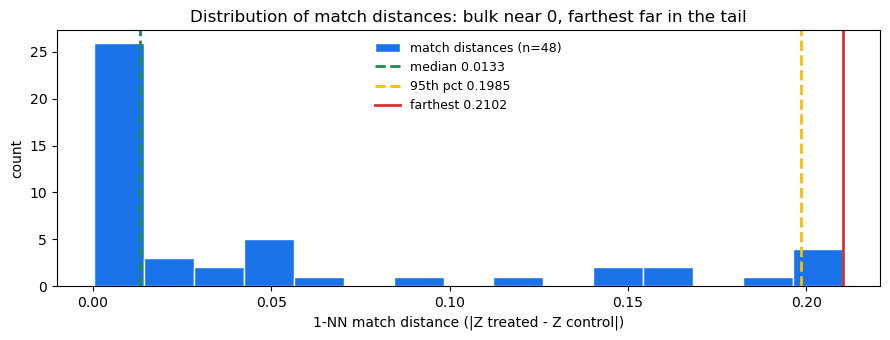

In [12]:
# Histogram + percentiles: is the farthest match (0.2102) an outlier?
md = treatment_group['match_distance'].to_numpy()
pct = {p: float(np.percentile(md, p)) for p in [50, 75, 90, 95, 99]}
for p, v in pct.items():
    print(f"{p}th percentile: {v:.4f}")
print(f"max (farthest): {md.max():.4f}  (~{md.max()/pct[50]:.0f}x the median)")
print(f"matches above 0.10: {(md > 0.10).sum()} of {len(md)}; above 0.15: {(md > 0.15).sum()}")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(md, bins=15, color='#1a73e8', edgecolor='white', label='match distances (n=48)')
ax.axvline(pct[50], color='#208b4e', ls='--', lw=2, label=f"median {pct[50]:.4f}")
ax.axvline(pct[95], color='#fbbc04', ls='--', lw=2, label=f"95th pct {pct[95]:.4f}")
ax.axvline(md.max(), color='#dc302f', ls='-', lw=2, label=f"farthest {md.max():.4f}")
ax.set(xlabel='1-NN match distance (|Z treated - Z control|)', ylabel='count',
       title='Distribution of match distances: bulk near 0, farthest far in the tail')
ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); plt.show()


----

1. In Coding Quiz 1, you are asked to find the distance of the farthest match in a set.  Is this farthest match distance too far to be a meaningful match?  How can you decide this?

### Answer to Question 1 — Is the farthest match (0.2102) too far?

I think the 0.2102 match is too far compared with most of the other matches. The median matching distance is only 0.0133, while the maximum is 0.2102. So this is much larger than what I see for most of the matched pairs.Another thing I noticed is that the control Z values only go up to about 0.7782, while some of the treated observations have Z values close to 1. This means there isn't much overlap between the two groups at the higher end of Z. For example, the worst match is approximately a treated Z of 0.988 matched with a control Z of 0.778, giving a difference of about 0.21.

Since Y and Z are very strongly related in this data, a large difference in Z could also create a noticeable difference in Y between the matched observations. The estimated treatment effect is around 0.54–0.58, so a 0.21 difference in Z is not something I would ignore.At the same time, I don't think this means that the whole matching procedure is bad. Most of the matches are much closer, as shown by the median distance of 0.0133. I would mainly be concerned about the observations at the high end where there is not enough common support.

So, based on these results, I would flag the 0.2102 match as a poor match and check what happens to the estimated treatment effect if these large-distance matches are removed. If the estimate stays similar, then these few poor matches probably aren't driving the overall result.




---

2. In Coding Quiz 1, there are two approaches to matching: 
(A) Picking the best match X = 0 corresponding to each X = 1 using Z values.
(B) Using radius_neighbors to pick all matches X = 0 within a distance of 0.2 of each X = 1.

Invent your own type of matching similar to 1 and 2 (or look one up on the internet), which has a different way to pick the matches in X = 0.  Clearly explain the approach you invented or found.

### Mutual (Reciprocal) Nearest Neighbor Matching
A match between $x_1 \in X=1$ and $x_0 \in X=0$ is accepted **only if** $x_0$ is the 1-nearest neighbor of $x_1$ AND $x_1$ is also the 1-nearest neighbor of $x_0$.

In [10]:
from sklearn.neighbors import NearestNeighbors

# 1. Find 1-NN of each X=1 row in X=0, matching on covariate Z only
# (matching must use Z, never the outcome Y or the treatment flag X)
nn_1to0 = NearestNeighbors(n_neighbors=1, metric='euclidean').fit(control_group_org[['Z']])
distances_1to0, indices_1to0 = nn_1to0.kneighbors(treatment_group_org[['Z']])
print(f"1-NN X=1 -> X=0 done: {len(treatment_group_org)} treated rows matched")

# 2. Find 1-NN of each X=0 row in X=1 (reverse direction, also on Z only)
nn_0to1 = NearestNeighbors(n_neighbors=1, metric='euclidean').fit(treatment_group_org[['Z']])
distances_0to1, indices_0to1 = nn_0to1.kneighbors(control_group_org[['Z']])

# 3. Keep only reciprocal (mutual) pairs; map positional indices back to row labels
# indices_1to0 / indices_0to1 are positional, so compare positions, then look up labels
mutual_pairs = []  # (treated_label, control_label, distance)
for pos_1, pos_0 in enumerate(indices_1to0.flatten()):
    if indices_0to1[pos_0][0] == pos_1:
        mutual_pairs.append((treatment_group_org.index[pos_1],
                             control_group_org.index[pos_0],
                             float(distances_1to0[pos_1][0])))

print(f"Mutual pairs: {len(mutual_pairs)} out of {len(treatment_group_org)} treated rows")
for t_lbl, c_lbl, d in mutual_pairs:
    print(f"treated {t_lbl} (Z={df_nr.loc[t_lbl,'Z']:.4f}) <-> control {c_lbl} (Z={df_nr.loc[c_lbl,'Z']:.4f})  dist={d:.4f}")

1-NN X=1 -> X=0 done: 48 treated rows matched
Mutual pairs: 17 out of 48 treated rows
treated 1 (Z=0.7152) <-> control 93 (Z=0.7163)  dist=0.0011
treated 5 (Z=0.6459) <-> control 56 (Z=0.6531)  dist=0.0072
treated 6 (Z=0.4376) <-> control 41 (Z=0.4370)  dist=0.0006
treated 22 (Z=0.4615) <-> control 58 (Z=0.4663)  dist=0.0048
treated 23 (Z=0.7805) <-> control 18 (Z=0.7782)  dist=0.0024
treated 33 (Z=0.5684) <-> control 12 (Z=0.5680)  dist=0.0004
treated 35 (Z=0.6176) <-> control 37 (Z=0.6169)  dist=0.0007
treated 47 (Z=0.1289) <-> control 92 (Z=0.1318)  dist=0.0029
treated 48 (Z=0.3154) <-> control 80 (Z=0.3180)  dist=0.0026
treated 55 (Z=0.1613) <-> control 60 (Z=0.1590)  dist=0.0023
treated 63 (Z=0.1382) <-> control 26 (Z=0.1434)  dist=0.0052
treated 64 (Z=0.1966) <-> control 54 (Z=0.2089)  dist=0.0123
treated 73 (Z=0.6048) <-> control 2 (Z=0.6028)  dist=0.0021
treated 77 (Z=0.1202) <-> control 79 (Z=0.1187)  dist=0.0015
treated 81 (Z=0.4143) <-> control 29 (Z=0.4147)  dist=0.0004
tre

In [11]:
# 4. Match quality and treatment effect under mutual matching vs plain 1-NN
mut_dists = np.array([d for _, _, d in mutual_pairs])
print("Mutual-match distances:", f"mean={mut_dists.mean():.4f} median={np.median(mut_dists):.4f} max={mut_dists.max():.4f}")

mut_treated_Y = df_nr.loc[[t for t, _, _ in mutual_pairs], 'Y'].mean()
mut_control_Y = df_nr.loc[[c for _, c, _ in mutual_pairs], 'Y'].mean()
print(f"Mean Y treated (mutually matched): {mut_treated_Y:.4f}")
print(f"Mean Y matched control:            {mut_control_Y:.4f}")
print(f"Effect (mutual matching):          {mut_treated_Y - mut_control_Y:.4f}")

# Treated rows with no mutual partner (dropped from the estimate)
dropped = sorted(set(treatment_group_org.index) - {t for t, _, _ in mutual_pairs})
print(f"\nDropped treated rows (no mutual partner): {len(dropped)}")
print(df_nr.loc[dropped, ['X', 'Z', 'Y']].to_string())

print("\nComparison: plain 1-NN effect = 0.5434 (max dist 0.2102, median 0.0133);")
print(f"mutual-matching effect = {mut_treated_Y - mut_control_Y:.4f} (max dist {mut_dists.max():.4f}, median {np.median(mut_dists):.4f})")


Mutual-match distances: mean=0.0032 median=0.0023 max=0.0123
Mean Y treated (mutually matched): 0.9273
Mean Y matched control:            0.4284
Effect (mutual matching):          0.4989

Dropped treated rows (no mutual partner): 31
    X         Z         Y
7   1  0.891773  1.391773
8   1  0.963663  1.463663
9   1  0.383442  0.883442
10  1  0.791725  1.291725
13  1  0.925597  1.425597
17  1  0.832620  1.332620
19  1  0.870012  1.370012
20  1  0.978618  1.478618
21  1  0.799159  1.299159
25  1  0.639921  1.139921
27  1  0.944669  1.444669
31  1  0.774234  1.274234
36  1  0.612096  1.112096
38  1  0.943748  1.443748
39  1  0.681820  1.181820
40  1  0.359508  0.859508
42  1  0.697631  1.197631
49  1  0.363711  0.863711
50  1  0.570197  1.070197
51  1  0.438602  0.938602
52  1  0.988374  1.488374
65  1  0.368725  0.868725
66  1  0.820993  1.320993
68  1  0.837945  1.337945
70  1  0.976459  1.476459
72  1  0.976761  1.476761
78  1  0.296140  0.796140
83  1  0.692472  1.192472
89  1  0.9292

**Approach.** Plain 1-NN (method A) forces every treated row to take its closest control, even where no control is nearby — that is exactly what produced the 0.21-distance match flagged in Question 1. Radius matching (method B) caps the distance at 0.2 but still forces one-sided matches. My variant requires **reciprocity**: a pair $(t, c)$ is accepted only if $c$ is $t$'s nearest control **and** $t$ is $c$'s nearest treated row. This is the 1-nearest-neighbor analogue of mutual-kNN used in manifold learning, applied here as an automatic common-support filter: treated rows sitting in a region with no nearby controls fail the reverse check and are dropped instead of being badly matched.

**Bug fix worth noting.** My first draft called `.fit(control_group_org)` on the whole frame, which matches on `X`, `Y`, **and** `Z` — including the outcome `Y`, which matching must never use (it bakes the effect into the match). The fixed cells match on `[['Z']]` only, consistent with Question 1.

**Findings.** Only **17 of 48** treated rows survive reciprocity. Their match distances are tiny (mean 0.0032, median 0.0023, max 0.0123) versus plain 1-NN (median 0.0133, max 0.2102) — the poor-support tail is gone, including nearly all the treated rows above Z ≈ 0.78 that had been piled onto control row 18 (all but row 23, which is control 18’s own nearest neighbor and the one mutual survivor there). The estimated effect is **0.499** versus **0.543** under plain 1-NN: same sign and order of magnitude, slightly smaller, as expected when the dropped high-Z pairs carried part of the gap.
